In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("data/cleaned_car_data.csv")
df.head()

,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,car_age,brand
0,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,12,Maruti
1,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,12,Skoda
2,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,20,Honda
3,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,16,Hyundai
4,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,19,Maruti


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

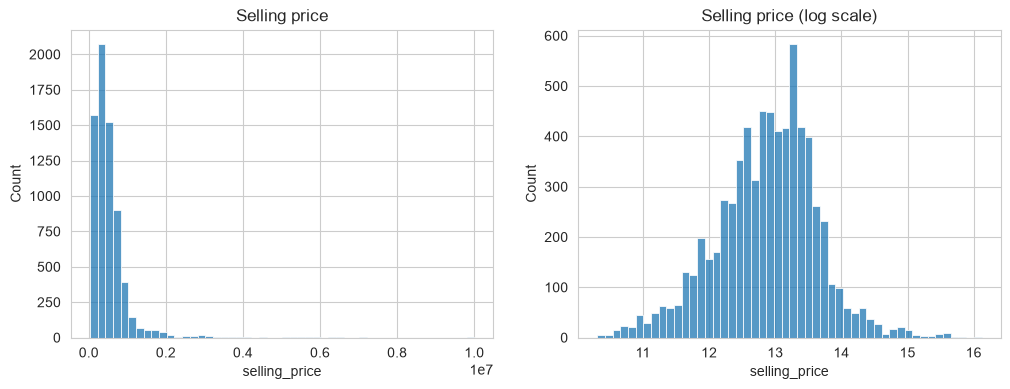

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["selling_price"], bins=50, ax=ax[0])
ax[0].set_title("Selling price")

sns.histplot(np.log1p(df["selling_price"]), bins=50, ax=ax[1])
ax[1].set_title("Selling price (log scale)")

plt.show()

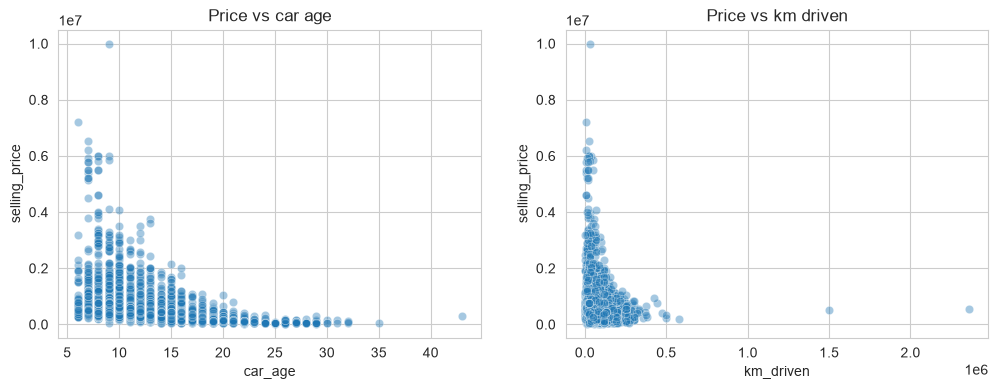

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.scatterplot(x="car_age", y="selling_price", data=df, alpha=0.4, ax=ax[0])
ax[0].set_title("Price vs car age")

sns.scatterplot(x="km_driven", y="selling_price", data=df, alpha=0.4, ax=ax[1])
ax[1].set_title("Price vs km driven")

plt.show()

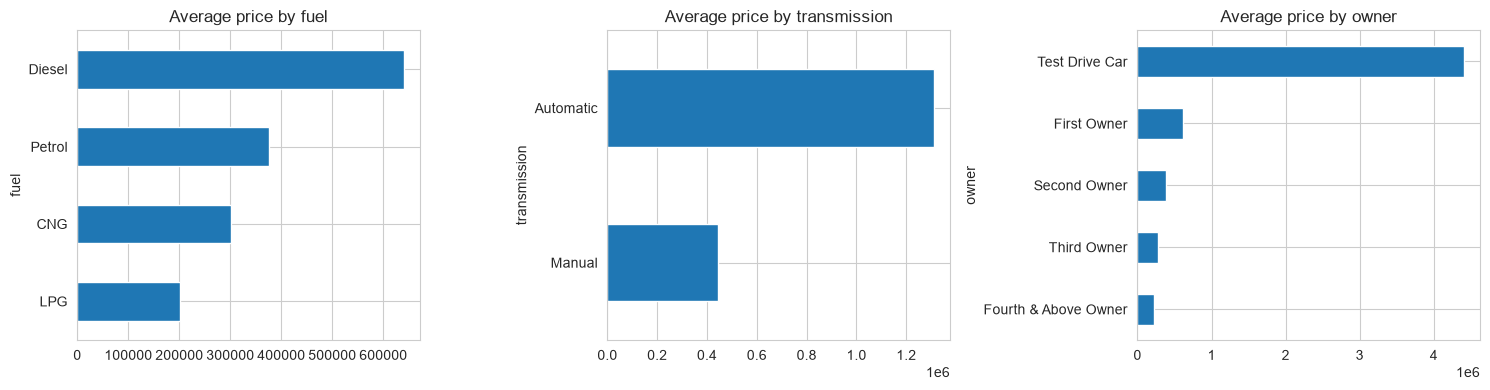

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(["fuel", "transmission", "owner"]):
    df.groupby(col)["selling_price"].mean().sort_values().plot(kind="barh", ax=ax[i])
    ax[i].set_title(f"Average price by {col}")

plt.tight_layout()
plt.show()

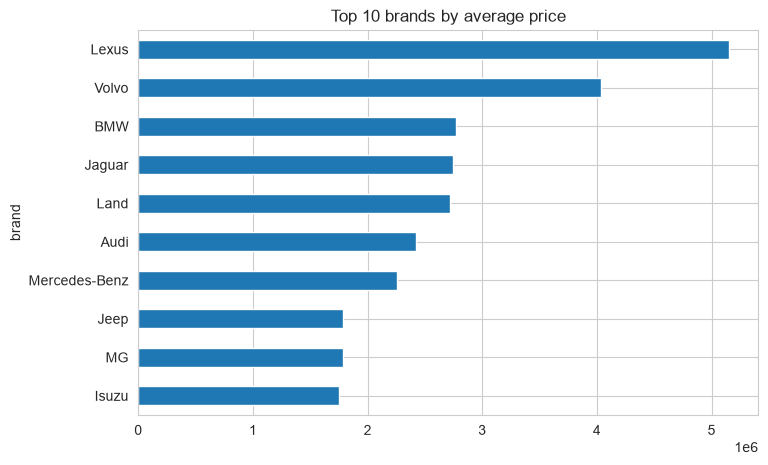

In [7]:
top_brands = df.groupby("brand")["selling_price"].mean().sort_values(ascending=False).head(10)
top_brands.sort_values().plot(kind="barh")
plt.title("Top 10 brands by average price")
plt.show()

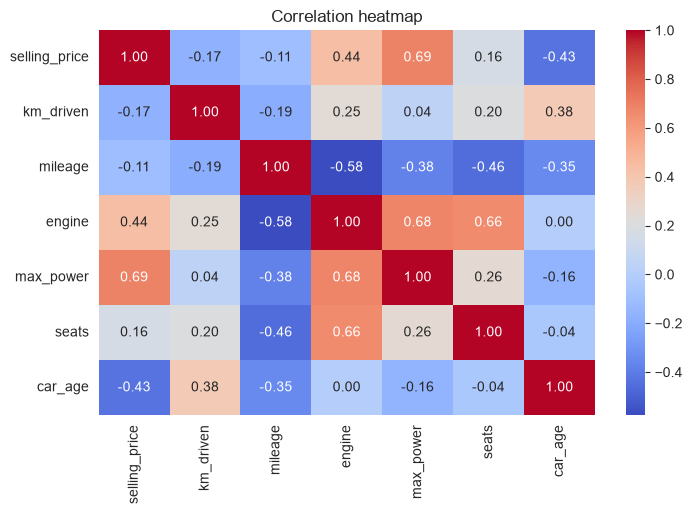

In [8]:
num_cols = ["selling_price", "km_driven", "mileage", "engine", "max_power", "seats", "car_age"]

sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()